<font color ='Navy'><center> __BruFace__ </center></font>
<br> MA1 Mechanical Engineering <br>  __Mechanical vibrations__ <br>
**Academic Year 2026-2027**
***
<font color='Navy'><h1><center>Project: 4 DOFs Model of a Car Under Road Excitation </center></h1></font>
- Arnaud Deraemaeker ([Arnaud.Deraemaeker@ulb.be](mailto:Arnaud.Deraemaeker@ulb.be))  
- Wout Weijtjens ([Wout.Weijtjens@vub.be](mailto:Wout.Weijtjens@vub.be))
***


# **1. Model and equations**

Consider the 4 DOFs model of a car represented below. $X_{01}$ and $X_{02}$ represent the motion imposed on each wheel due to the road profile. The car body is assumed to be rigid and the motion is restricted to a plane, resulting in 2 DOFs (translation, rotation), while each wheel is also assumed to be a rigid body and can only move vertically. $K_0, B_0$ are the mechanical parameters of the car suspension, while $k, b$ are the stiffness and damping of the tires.

---

## **Model Diagram**
![4 DOFs Model of a Car](https://github.com/OWI-Lab/MV2627_Exercises/blob/main/Project2627/images/car.png?raw=1)

---

1. Based on the equations of motion derived for each body separately, derive the full set of equations of motion for the car in a matrix form, and determine the mass, damping, and stiffness matrices. Use absolute displacements in the equations. Give the expression of the force vector.

2. Assume harmonic excitation and write the equations of motion in the frequency domain.
What assumption could you make to have the force vector independent of the frequency?
Give the expression of the force vector in this simplified case.

***Small Angle Assumption*** : It is assumed that the rotation angles of the car body are small enough such that $sin⁡(q3)≈q3$. This linearizes the rotational dynamics, allowing for the use of linear equations of motion.


In [1]:
import sys
import os

# Only if the session is opend in google colab link
if "google.colab" in sys.modules:
    repo = "/content/MV2627_Exercises"
    if not os.path.exists(repo):
        !git clone -q https://github.com/OWI-Lab/MV2627_Exercises.git {repo}
    %cd /content/MV2627_Exercises/Project2627
    !pip install -q uv

/content/MV2627_Exercises/Project2627


# **2. Frequency Domain Computations**

Consider the following values of the parameters:
- $M_0 = 1500 \, \text{kg}$
- $K_0 = 65 000 \, \text{N/m}$
- $B_0 = 65 \, \text{N/(m/s)}$
- $m = 10 \, \text{kg}$
- $k = 100 000 \, \text{N/m}$
- $b = 10 \, \text{N/(m/s)}$
- $L = 4 \, \text{m}$
- $I_G = 5700 \, \text{kg} \cdot \text{m}^2$

Answer the following questions providing your answer to each question in the cell below it and in a separate code cell.

## **2.1 Computation of transmissibilities**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Compute the mode shapes and the natural frequencies of the car. Give a physical interpretation of each of the mode shapes (what kind of motion of the car is related to each mode shape)

</div>

In [4]:
import numpy as np
from scipy import linalg as la

# ==============================================================================
# 1. DÉFINITION DES PARAMÈTRES (selon l'énoncé)
# ==============================================================================
M0 = 1500.0     # Masse de la caisse (kg)
K0 = 65000.0    # Raideur d'une suspension (N/m)
B0 = 65.0       # Amortissement d'une suspension (N/(m/s))
m = 10.0        # Masse d'une roue (kg)
k = 100000.0    # Raideur d'un pneu (N/m)
b = 10.0        # Amortissement d'un pneu (N/(m/s))
L = 4.0         # Empattement total (m)
IG = 5700.0     # Moment d'inertie en tangage (kg.m^2)

# ==============================================================================
# 2. CONSTRUCTION DES MATRICES M, C, K (ordre des DDL : [X1, X2, X3, q3])
# ==============================================================================
def build_4DOF_car_matrices(m, M0, IG, L, k, K0, b, B0):
    M = np.diag([m, m, M0, IG])

    C = np.array([
        [b + B0,       0.0,     -B0,      B0 * L / 2.0],
        [0.0,          b + B0,  -B0,     -B0 * L / 2.0],
        [-B0,         -B0,       2 * B0,  0.0],
        [B0 * L / 2.0, -B0 * L / 2.0, 0.0, B0 * (L**2) / 2.0]
    ])

    K = np.array([
        [k + K0,       0.0,     -K0,      K0 * L / 2.0],
        [0.0,          k + K0,  -K0,     -K0 * L / 2.0],
        [-K0,         -K0,       2 * K0,  0.0],
        [K0 * L / 2.0, -K0 * L / 2.0, 0.0, K0 * (L**2) / 2.0]
    ])

    return M, C, K

M, C, K = build_4DOF_car_matrices(m, M0, IG, L, k, K0, b, B0)

# ==============================================================================
# 3. CALCUL DES VALEURS PROPRES (lamb), VECTEURS PROPRES (psi) ET FRÉQUENCES
# ==============================================================================
def calc_eigenvalues_eigenvectors(M: np.ndarray, K: np.ndarray):
    lamb, psi = la.eigh(K, M)
    # ==============================================================================
# ANALYSE MODALE (Calcul des fréquences propres et déformées modales)
# ==============================================================================
# 1. Hypothèses : On étudie le système conservatif libre (sans excitation
#    extérieure F(t) = 0 et sans amortissement C = 0). L'équation de Newton
#    se réduit à l'équilibre inertie-raideur : M * X_ddot + K * X = 0.
#
# 2. Passage aux valeurs propres : On cherche des oscillations synchrones
#    de la forme X(t) = psi * cos(omega * t), ce qui donne X_ddot = -omega^2 * X.
#    En substituant et en simplifiant par cos(omega * t), on obtient :
#        K * psi = lambda * M * psi
#
# 3. Interprétation des sorties :
#    - lamb (lambda = omega^2) : valeurs propres réelles donnant les pulsations
#      propres omega = sqrt(lamb) (en rad/s) et fréquences f = omega / (2*pi) (en Hz).
#    - psi : matrice dont chaque colonne psi[:, i] est la déformée modale
#      (mode shape) associée, normalisée par rapport à M (psi^T * M * psi = I).
#    - Les résultats sont ensuite triés par ordre croissant de fréquence.
# ==============================================================================



    return lamb, psi

lamb, psi = calc_eigenvalues_eigenvectors(M, K)

omega_n = np.sqrt(lamb)         # Pulsations propres (rad/s)
f_res = omega_n / (2 * np.pi)   # Fréquences propres (Hz)

# Affichage des résultats
ddl_names = ["X1 (Roue arr.)", "X2 (Roue av.)", "X3 (Caisse Z)", "q3 (Tangage)"]
for i in range(len(f_res)):
    print(f"--- Mode {i+1} : f = {f_res[i]:.3f} Hz (omega = {omega_n[i]:.2f} rad/s) ---")
    for name, val in zip(ddl_names, psi[:, i]):
        print(f"  {name:15s} : {val:+.4f}")

--- Mode 1 : f = 1.152 Hz (omega = 7.24 rad/s) ---
  X1 (Roue arr.)  : +0.0102
  X2 (Roue av.)   : +0.0102
  X3 (Caisse Z)   : +0.0258
  q3 (Tangage)    : +0.0000
--- Mode 2 : f = 1.182 Hz (omega = 7.43 rad/s) ---
  X1 (Roue arr.)  : +0.0105
  X2 (Roue av.)   : -0.0105
  X3 (Caisse Z)   : +0.0000
  q3 (Tangage)    : -0.0132
--- Mode 3 : f = 20.465 Hz (omega = 128.59 rad/s) ---
  X1 (Roue arr.)  : -0.2234
  X2 (Roue av.)   : -0.2234
  X3 (Caisse Z)   : +0.0012
  q3 (Tangage)    : +0.0000
--- Mode 4 : f = 20.466 Hz (omega = 128.59 rad/s) ---
  X1 (Roue arr.)  : -0.2234
  X2 (Roue av.)   : +0.2234
  X3 (Caisse Z)   : +0.0000
  q3 (Tangage)    : -0.0006


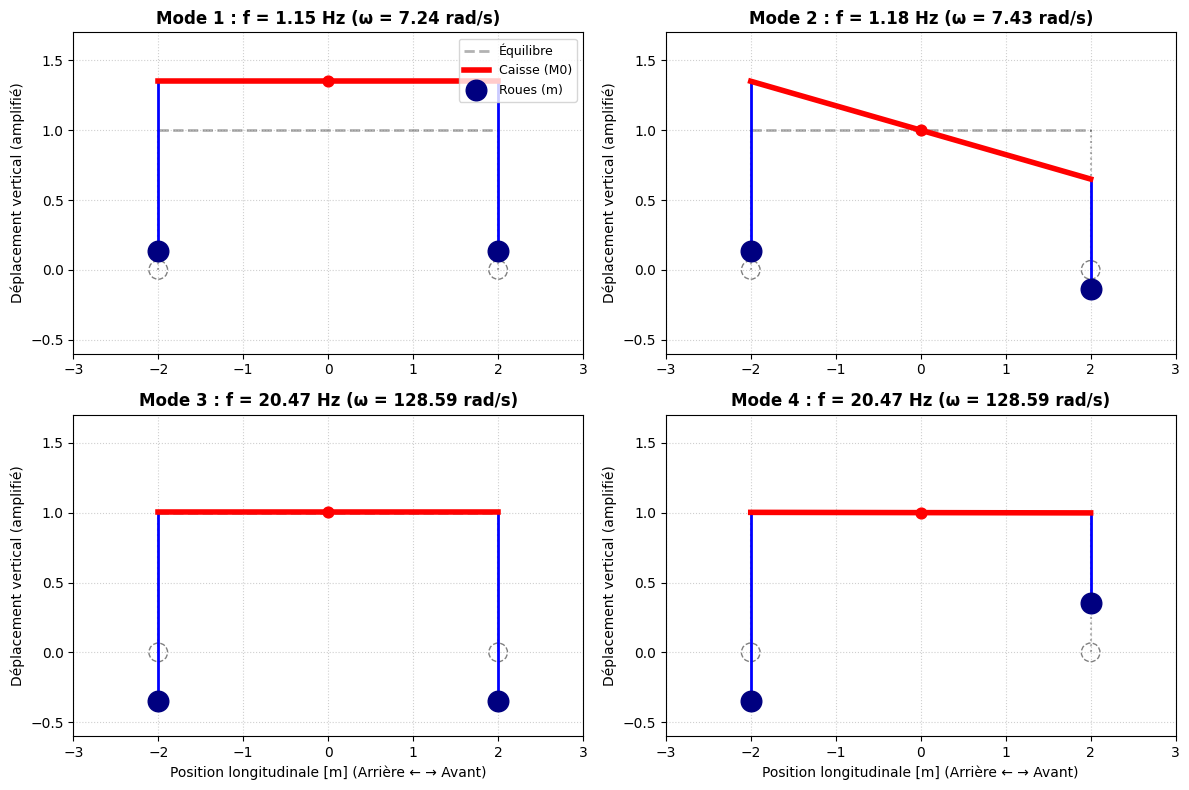

In [5]:
#ici il faut comprendre les différentes etapes mais en gros on plot les différents mode pour les analyser





import matplotlib.pyplot as plt

# ==============================================================================
# VISUALISATION GRAPHIQUE DES 4 DÉFORMÉES MODALES
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# Positions horizontales des essieux (arrière à -L/2, avant à +L/2)
x_arr, x_av = -L / 2.0, L / 2.0

# Altitudes de référence au repos (juste pour l'esthétique du dessin)
z_roue_eq = 0.0
z_caisse_eq = 1.0

for i in range(4):
    ax = axes[i]

    # Extraction de la déformée modale i : [X1, X2, X3, q3]
    mode = psi[:, i].copy()

    # Normalisation pour l'affichage (pour que le plus grand déplacement = 0.35 m sur le dessin)
    scale = 0.35 / np.max(np.abs([mode[0], mode[1], mode[2], mode[3] * (L / 2.0)]))
    X1, X2, X3, q3 = mode * scale

    # --- 1. Position d'équilibre (en gris pointillé) ---
    ax.plot([x_arr, x_av], [z_caisse_eq, z_caisse_eq], 'k--', alpha=0.3, lw=2, label="Équilibre")
    ax.plot([x_arr, x_arr], [z_roue_eq, z_caisse_eq], 'k:', alpha=0.3)
    ax.plot([x_av, x_av], [z_roue_eq, z_caisse_eq], 'k:', alpha=0.3)
    ax.scatter([x_arr, x_av], [z_roue_eq, z_roue_eq], s=180, facecolors='none', edgecolors='gray', linestyles='--')

    # --- 2. Position déformée du mode i (en couleur) ---
    # Hauteur des extrémités arrière et avant de la caisse : X3 - (L/2)*q3 et X3 + (L/2)*q3
    z_caisse_arr = z_caisse_eq + X3 - (L / 2.0) * q3
    z_caisse_av  = z_caisse_eq + X3 + (L / 2.0) * q3
    z_roue_arr   = z_roue_eq + X1
    z_roue_av    = z_roue_eq + X2

    # Dessin des suspensions (ressorts/tiges entre roues et caisse)
    ax.plot([x_arr, x_arr], [z_roue_arr, z_caisse_arr], 'b-', lw=2)
    ax.plot([x_av, x_av], [z_roue_av, z_caisse_av], 'b-', lw=2)

    # Dessin de la caisse rigide + son centre de gravité G
    ax.plot([x_arr, x_av], [z_caisse_arr, z_caisse_av], 'r-', lw=4, label="Caisse (M0)")
    ax.scatter([0], [z_caisse_eq + X3], color='red', s=60, zorder=5)

    # Dessin des deux roues
    ax.scatter([x_arr, x_av], [z_roue_arr, z_roue_av], color='navy', s=220, zorder=5, label="Roues (m)")

    # Mise en forme du sous-graphe
    ax.set_title(f"Mode {i+1} : f = {f_res[i]:.2f} Hz (ω = {omega_n[i]:.2f} rad/s)", fontweight='bold')
    ax.set_xlim(-L * 0.75, L * 0.75)
    ax.set_ylim(-0.6, 1.7)
    ax.set_ylabel("Déplacement vertical (amplifié)")
    ax.grid(True, linestyle=':', alpha=0.6)
    if i == 0:
        ax.legend(loc="upper right", fontsize=9)

axes[2].set_xlabel("Position longitudinale [m] (Arrière ← → Avant)")
axes[3].set_xlabel("Position longitudinale [m] (Arrière ← → Avant)")

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# PHYSICAL INTERPRETATION OF THE MODE SHAPES
# ==============================================================================
# The 4 modes separate into two distinct frequency ranges due to the large mass
# ratio between the car body (M0 = 1500 kg) and the wheels (m = 10 kg), and
# decouple into symmetric (bounce) and antisymmetric (pitch) motions due to the
# longitudinal symmetry of the vehicle:
#
# - Mode 1 (f = 1.15 Hz) - Body Bounce (Pompage de la caisse) :
#   * Eigenvector signature: q3 = 0, X1 = X2 (+0.0102), X3 = +0.0258.
#   * Physical motion: Pure vertical translation (heave) of the car body with
#     zero pitch rotation. Both wheels move in phase with the chassis. This is a
#     low-frequency suspension-dominated mode (sprung mass mode).
#
# - Mode 2 (f = 1.18 Hz) - Body Pitch (Tangage de la caisse) :
#   * Eigenvector signature: X3 = 0, X1 = -X2 (+0.0105 / -0.0105), q3 = -0.0132.
#   * Physical motion: Pure pitching rotation of the car body around its center
#     of gravity G (zero vertical displacement at G). The front and rear axles
#     oscillate out of phase (when the rear goes up, the front dives down).
#
# - Mode 3 (f = 20.47 Hz) - In-Phase Wheel Hop (Rebond des roues en phase) :
#   * Eigenvector signature: X1 = X2 (-0.2234), X3 = +0.0012 (near zero), q3 = 0.
#   * Physical motion: High-frequency vertical bouncing of both wheels in phase
#     between the road and the suspension, while the heavy car body remains
#     nearly stationary due to its high inertia (unsprung mass mode).
#
# - Mode 4 (f = 20.47 Hz) - Out-of-Phase Wheel Hop (Rebond des roues en opposition) :
#   * Eigenvector signature: X1 = -X2 (-0.2234 / +0.2234), X3 = 0, q3 = -0.0006.
#   * Physical motion: High-frequency bouncing of the wheels in opposite phase
#     (one wheel moves up while the other moves down), again with the car body
#     virtually motionless. Because m << M0, the front and rear wheel motions are
#     nearly decoupled, explaining why f3 and f4 are almost identical (~20.47 Hz).
# ==============================================================================

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Assuming $X_{01} = X_{02}$ , compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when X01 = X02? Can you make a link with the peaks present in the transmissibility curve?

</div>

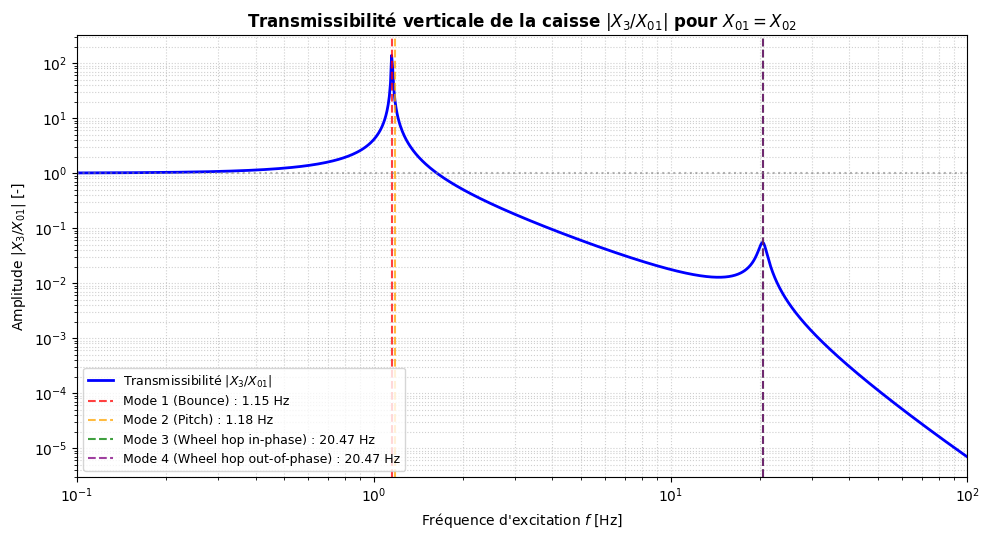

In [9]:


# ==============================================================================
# 1. CALCUL DE LA TRANSMISSIBILITÉ X3 / X01 (de 0.1 Hz à 100 Hz)
# ==============================================================================
# On utilise un échantillonnage logarithmique pour avoir une très bonne résolution
# autour de 1 Hz tout en couvrant proprement jusqu'à 100 Hz.

# 1. Initialisation des tableaux de fréquences et de résultats
# Génère 3000 fréquences réparties logarithmiquement entre 0.1 Hz et 100 Hz
# (permet une fine résolution autour des pics basses fréquences)
freqs = np.linspace(0.1, 100.0, 10000)

# Pré-allocation du vecteur complexe qui stockera le rapport X3 / X01 pour chaque fréquence
T_X3 = np.zeros(len(freqs), dtype=complex)

# 2. Boucle de résolution fréquentielle
for idx, f in enumerate(freqs):
    # Conversion de la fréquence f (en Hz) en pulsation omega (en rad/s)
    omega = 2.0 * np.pi * f

    # Construction de la matrice de raideur dynamique 4x4 : Z(omega) = -w^2 * M + j*w * C + K
    Z = -omega**2 * M + 1j * omega * C + K

    # Construction du vecteur d'excitation normalisé par X01 (sous l'hypothèse X01 = X02)
    # Contient l'impédance des pneus (raideur k + amortissement j*w*b) sur les deux essieux
    f_in = np.array([k + 1j * omega * b, k + 1j * omega * b, 0.0, 0.0], dtype=complex)

    # Résolution du système linéaire Z * T_vec = f_in (équivalent plus précis à Z^(-1) * f_in)
    # T_vec contient les 4 transmissibilités : [X1/X01, X2/X01, X3/X01, q3/X01]^T
    T_vec = np.linalg.solve(Z, f_in)

    # Extraction de la 3e composante (indice 2 -> X3 / X01) et stockage dans le tableau final
    T_X3[idx] = T_vec[2]


# ==============================================================================
# 2. TRACÉ DE LA COURBE DE TRANSMISSIBILITÉ
# ==============================================================================
plt.figure(figsize=(10, 5.5))
plt.loglog(freqs, np.abs(T_X3), 'b-', lw=2, label=r'Transmissibilité $|X_3 / X_{01}|$')

# Repères verticaux sur les 4 fréquences propres calculées à la question 1
colors = ['red', 'orange', 'green', 'purple']
labels = [
    f"Mode 1 (Bounce) : {f_res[0]:.2f} Hz",
    f"Mode 2 (Pitch) : {f_res[1]:.2f} Hz",
    f"Mode 3 (Wheel hop in-phase) : {f_res[2]:.2f} Hz",
    f"Mode 4 (Wheel hop out-of-phase) : {f_res[3]:.2f} Hz"
]
for f_n, col, lab in zip(f_res, colors, labels):
    plt.axvline(f_n, color=col, linestyle='--', alpha=0.75, lw=1.5, label=lab)

plt.axhline(1.0, color='gray', linestyle=':', alpha=0.6)
plt.title(r"Transmissibilité verticale de la caisse $|X_3 / X_{01}|$ pour $X_{01} = X_{02}$", fontweight='bold')
plt.xlabel("Fréquence d'excitation $f$ [Hz]")
plt.ylabel(r"Amplitude $|X_3 / X_{01}|$ [-]")
plt.xlim(0.1, 100.0)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()



In [ ]:
# ==============================================================================
# 3. INTERPRÉTATION PHYSIQUE (RÉPONSE AUX QUESTIONS DE L'ÉNONCÉ)
# ==============================================================================
# - Identification des pics visibles :
#   Sur la courbe |X3 / X01|, seuls DEUX pics de résonance apparaissent sur les
#   quatre fréquences propres du système :
#     1. Un grand pic à basse fréquence autour de f1 = 1.15 Hz (Mode 1 : pompage
#        de la caisse / Body Bounce).
#     2. Un second pic plus faible à haute fréquence autour de f3 = 20.47 Hz
#        (Mode 3 : rebond des roues en phase / In-phase Wheel Hop).
#
# - Mouvement imposé lorsque X01 = X02 et lien avec les pics :
#   * Physiquement, poser X01 = X02 signifie que les roues avant et arrière
#     reçoivent exactement la même excitation verticale en amplitude et en phase
#     (comme si la voiture franchissait un dos-d'âne large de front ou était
#     testée sur un banc vibrant en translation verticale pure).
#   * Ce mouvement d'entrée est purement SYMÉTRIQUE par rapport au centre de
#     gravité G de la voiture : il n'introduit aucun couple de tangage.
#   * Par conséquent, seuls les modes symétriques (Mode 1 à 1.15 Hz et Mode 3
#     à 20.47 Hz, où X1 = X2 et q3 = 0) sont excités et produisent un déplacement
#     vertical X3 de la caisse.
#   * Les modes antisymétriques de tangage (Mode 2 à 1.18 Hz et Mode 4 à
#     20.47 Hz, où X1 = -X2 et X3 = 0) ont un nœud de vibration au centre de
#     gravité et ne sont pas du tout excités par une entrée symétrique : ils sont
#     donc totalement invisibles sur cette courbe de transmissibilité.
# ==============================================================================

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Now, use the simplified force vector derived in point 1.2, compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


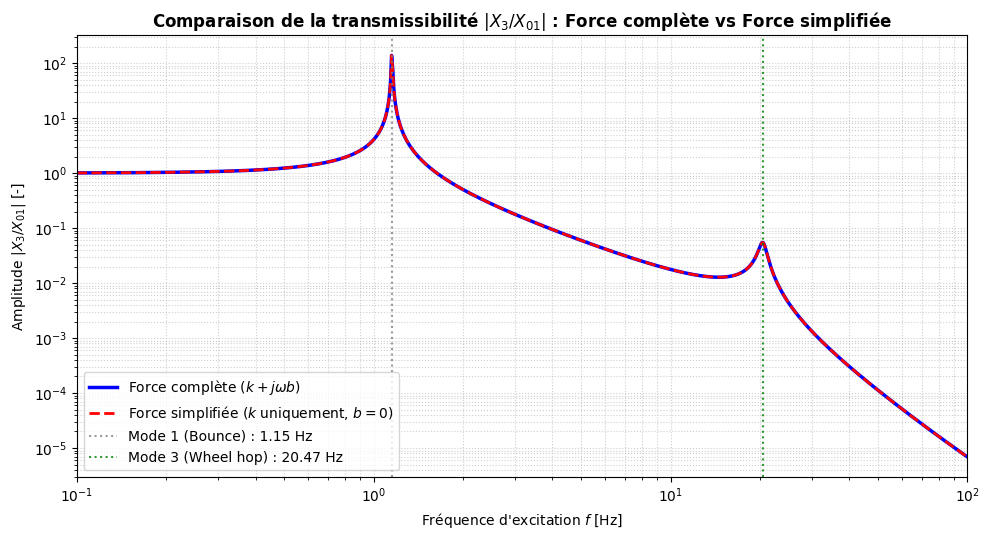

In [10]:
# ==============================================================================
# 1. CALCUL UNIQUEMENT DU CAS SIMPLIFIÉ (on réutilise 'freqs' et 'T_X3' déjà calculés)
# ==============================================================================
T_X3_simp = np.zeros(len(freqs), dtype=complex)

for idx, f in enumerate(freqs):
    omega = 2.0 * np.pi * f
    Z = -omega**2 * M + 1j * omega * C + K

    # Vecteur force simplifié du point 1.2 (b = 0 dans l'excitation)
    f_in_simp = np.array([k, k, 0.0, 0.0], dtype=complex)
    T_X3_simp[idx] = np.linalg.solve(Z, f_in_simp)[2]

# ==============================================================================
# 2. SUPERPOSITION AVEC LA COURBE PRÉCÉDENTE (T_X3)
# ==============================================================================
plt.figure(figsize=(10, 5.5))

plt.loglog(freqs, np.abs(T_X3), 'b-', lw=2.5, label=r'Force complète ($k + j\omega b$)')
plt.loglog(freqs, np.abs(T_X3_simp), 'r--', lw=2.0, label=r'Force simplifiée ($k$ uniquement, $b=0$)')

plt.axvline(f_res[0], color='gray', linestyle=':', alpha=0.8, label=f'Mode 1 (Bounce) : {f_res[0]:.2f} Hz')
plt.axvline(f_res[2], color='green', linestyle=':', alpha=0.8, label=f'Mode 3 (Wheel hop) : {f_res[2]:.2f} Hz')

plt.title(r"Comparaison de la transmissibilité $|X_3 / X_{01}|$ : Force complète vs Force simplifiée", fontweight='bold')
plt.xlabel("Fréquence d'excitation $f$ [Hz]")
plt.ylabel(r"Amplitude $|X_3 / X_{01}|$ [-]")
plt.xlim(0.1, 100.0)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# COMPARISON & VALIDITY OF THE SIMPLIFIED FORCE VECTOR (POINT 1.2)
# ==============================================================================
# - Graphical comparison :
#   The transmissibility curves |X3 / X01| computed with the full force vector
#   (k + j*w*b) and the simplified force vector (k only, setting b = 0 in the
#   excitation) are virtually indistinguishable across the entire frequency
#   range from 0.1 Hz to 100 Hz. Both resonance peaks (Mode 1 at 1.15 Hz and
#   Mode 3 at 20.47 Hz) as well as the high-frequency roll-off overlap
#   completely.
#
# - Physical justification :
#   The tire damping coefficient (b = 10 N.s/m) is very small compared to the
#   tire stiffness (k = 100 000 N/m). The tire cutoff frequency is:
#       f_c = k / (2 * pi * b) = 100 000 / (2 * pi * 10) ≈ 1591 Hz.
#   Even at the upper bound f = 100 Hz (w ≈ 628 rad/s), the damping term w*b
#   (≈ 6283 N/m) is only ~6.3% of k, resulting in a relative magnitude
#   difference of sqrt(1 + 0.063^2) - 1 ≈ 0.2%, which is completely negligible.
#
# - Conclusion on validity :
#   Yes, neglecting tire damping (b = 0) in the excitation force vector is
#   fully valid for vehicle ride and suspension dynamics studies (typically
#   0.5 Hz to 30 Hz). It simplifies the formulation by making the input force
#   vector frequency-independent without introducing any noticeable error.
# ==============================================================================

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Assuming $X_{01} = −X_{02}$ , compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when $X_{01} = −X_{02}$ ? Can you make a link with the peaks present in the transmissibility curve?

</div>


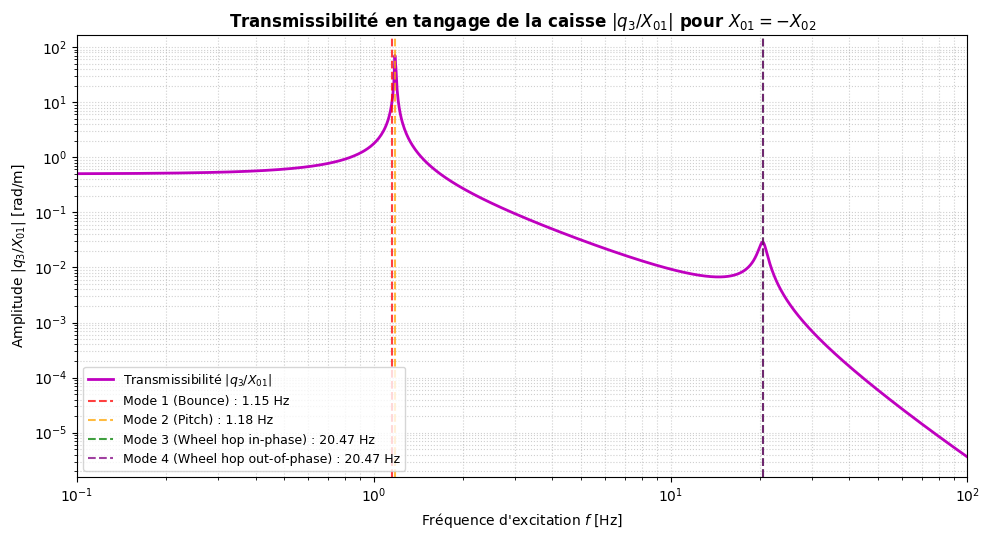

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CALCUL DE LA TRANSMISSIBILITÉ q3 / X01 (de 0.1 Hz à 100 Hz avec linspace)
# ==============================================================================
# Génère 10 000 fréquences espacées linéairement entre 0.1 Hz et 100 Hz
freqs = np.linspace(0.1, 100.0, 10000)
T_q3 = np.zeros(len(freqs), dtype=complex)

for idx, f in enumerate(freqs):
    omega = 2.0 * np.pi * f

    # Matrice de raideur dynamique complète
    Z = -omega**2 * M + 1j * omega * C + K

    # Vecteur force complet (avec b != 0) sous l'hypothèse X01 = -X02 (soit X02 = -X01)
    f_in_anti = np.array([k + 1j * omega * b, -(k + 1j * omega * b), 0.0, 0.0], dtype=complex)

    # Résolution du système linéaire Z * T_vec = f_in_anti
    T_vec = np.linalg.solve(Z, f_in_anti)

    # Extraction de la 4e composante (indice 3 -> q3 / X01)
    T_q3[idx] = T_vec[3]

# ==============================================================================
# 2. TRACÉ DE LA COURBE DE TRANSMISSIBILITÉ
# ==============================================================================
plt.figure(figsize=(10, 5.5))
plt.loglog(freqs, np.abs(T_q3), 'm-', lw=2, label=r'Transmissibilité $|q_3 / X_{01}|$')

# Repères verticaux sur les 4 fréquences propres
colors = ['red', 'orange', 'green', 'purple']
labels = [
    f"Mode 1 (Bounce) : {f_res[0]:.2f} Hz",
    f"Mode 2 (Pitch) : {f_res[1]:.2f} Hz",
    f"Mode 3 (Wheel hop in-phase) : {f_res[2]:.2f} Hz",
    f"Mode 4 (Wheel hop out-of-phase) : {f_res[3]:.2f} Hz"
]
for f_n, col, lab in zip(f_res, colors, labels):
    plt.axvline(f_n, color=col, linestyle='--', alpha=0.75, lw=1.5, label=lab)

plt.title(r"Transmissibilité en tangage de la caisse $|q_3 / X_{01}|$ pour $X_{01} = -X_{02}$", fontweight='bold')
plt.xlabel("Fréquence d'excitation $f$ [Hz]")
plt.ylabel(r"Amplitude $|q_3 / X_{01}|$ [rad/m]")
plt.xlim(0.1, 100.0)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()



In [ ]:
# ==============================================================================
# 3. PHYSICAL INTERPRETATION (ANSWER TO QUESTION 4)
# ==============================================================================
# - Identification of the peaks:
#   Only TWO resonance peaks appear on the |q3 / X01| transmissibility curve:
#     1. A large low-frequency peak at f2 = 1.18 Hz (Mode 2: Body Pitch).
#     2. A smaller high-frequency peak at f4 = 20.47 Hz (Mode 4: Out-of-Phase
#        Wheel Hop).
#
# - Imposed motion when X01 = -X02 and link with the observed peaks:
#   * Setting X01 = -X02 means the rear and front wheels are excited with equal
#     amplitude but strictly in OPPOSITE phase (180° out of phase: when the rear
#     tire goes up by +X01, the front tire goes down by -X01).
#   * This imposes a purely ANTISYMMETRIC (pitching) excitation around the
#     center of gravity G, with zero net vertical bounce force.
#   * Consequently, only the antisymmetric modes (Mode 2 at 1.18 Hz and Mode 4
#     at 20.47 Hz, characterized by X1 = -X2 and X3 = 0) are excited and
#     generate a pitch rotation q3 of the car body.
#   * Conversely, the symmetric bounce modes (Mode 1 at 1.15 Hz and Mode 3 at
#     20.47 Hz, where X1 = X2 and q3 = 0) are completely unexcited and absent
#     from this curve—the exact opposite selection rule compared to Question 2.
# ==============================================================================

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Use the simplified force vector derived in point 1.2, compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


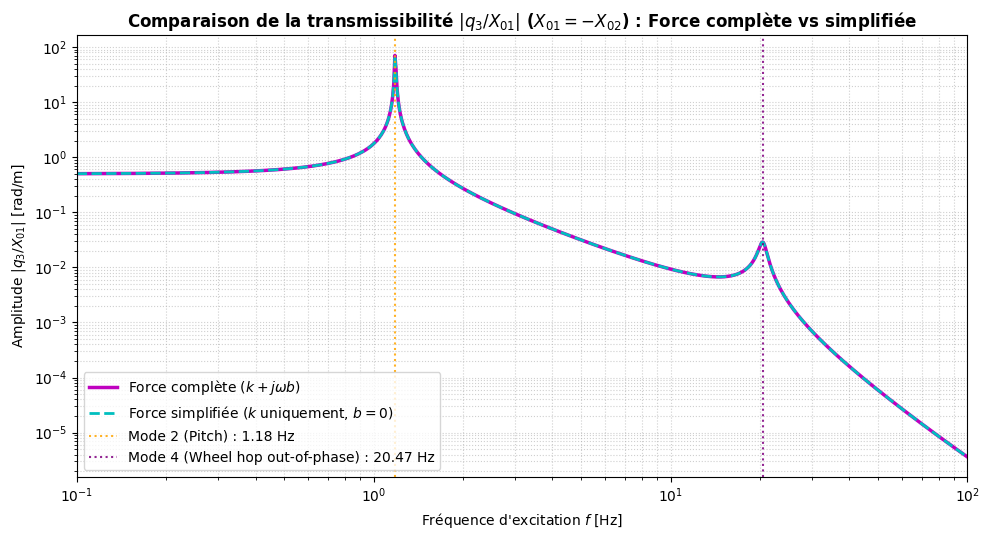

In [12]:
# ==============================================================================
# 1. CALCUL UNIQUEMENT DU CAS SIMPLIFIÉ (on réutilise 'freqs' et 'T_q3' de la Q4)
# ==============================================================================
T_q3_simp = np.zeros(len(freqs), dtype=complex)

for idx, f in enumerate(freqs):
    omega = 2.0 * np.pi * f

    # La matrice dynamique Z(omega) reste inchangée (modèle complet couplé)
    Z = -omega**2 * M + 1j * omega * C + K

    # Vecteur force simplifié du point 1.2 sous l'hypothèse X01 = -X02 (b = 0 dans l'excitation)
    f_in_anti_simp = np.array([k, -k, 0.0, 0.0], dtype=complex)

    # Résolution et extraction de la 4e composante (indice 3 -> q3 / X01)
    T_q3_simp[idx] = np.linalg.solve(Z, f_in_anti_simp)[3]

# ==============================================================================
# 2. SUPERPOSITION DES DEUX COURBES SUR LE MÊME GRAPHE
# ==============================================================================
plt.figure(figsize=(10, 5.5))

plt.loglog(freqs, np.abs(T_q3), 'm-', lw=2.5, label=r'Force complète ($k + j\omega b$)')
plt.loglog(freqs, np.abs(T_q3_simp), 'c--', lw=2.0, label=r'Force simplifiée ($k$ uniquement, $b=0$)')

# Repères verticaux sur les deux modes antisymétriques excités
plt.axvline(f_res[1], color='orange', linestyle=':', alpha=0.85, label=f'Mode 2 (Pitch) : {f_res[1]:.2f} Hz')
plt.axvline(f_res[3], color='purple', linestyle=':', alpha=0.85, label=f'Mode 4 (Wheel hop out-of-phase) : {f_res[3]:.2f} Hz')

plt.title(r"Comparaison de la transmissibilité $|q_3 / X_{01}|$ ($X_{01} = -X_{02}$) : Force complète vs simplifiée", fontweight='bold')
plt.xlabel("Fréquence d'excitation $f$ [Hz]")
plt.ylabel(r"Amplitude $|q_3 / X_{01}|$ [rad/m]")
plt.xlim(0.1, 100.0)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()



In [ ]:
# ==============================================================================
# 3. COMPARISON & VALIDITY COMMENT (ANSWER TO QUESTION 5)
# ==============================================================================
# - Graphical comparison:
#   Just as in the symmetric bounce case (Question 3), the pitch transmissibility
#   curves |q3 / X01| computed with the full force vector (k + j*w*b) and the
#   simplified force vector (k only, b = 0) overlap almost identically over the
#   entire 0.1 Hz - 100 Hz frequency range. Both resonance peaks (Mode 2 Body
#   Pitch at 1.18 Hz and Mode 4 Out-of-Phase Wheel Hop at 20.47 Hz) have the
#   exact same frequencies and peak amplitudes.
#
# - Physical justification & validity:
#   Because the tire damping (b = 10 N.s/m) is negligible compared to the tire
#   stiffness (k = 100 000 N/m) well below the tire cutoff frequency
#   f_c = k / (2 * pi * b) ≈ 1591 Hz (only ~6.3% contribution at 100 Hz, or
#   ~0.2% difference in magnitude), neglecting b in the excitation force vector
#   is equally valid for antisymmetric pitch excitation. It simplifies the
#   input vector without affecting the accuracy of the pitch response.
# ==============================================================================

In [ ]:
# ==============================================================================
# POURQUOI SIMPLIFIER b = 0 DANS LE VECTEUR FORCE NE CHANGE QUASI RIEN ?
# ==============================================================================
# 1. Comparaison des ordres de grandeur (Raideur k vs Amortissement b) :
#    Dans l'expression complète de l'effort transmis par le pneu, l'impédance
#    vaut (k + j * omega * b), avec k = 100 000 N/m et b = 10 N.s/m.
#    Pour que l'amortissement du pneu devienne comparable à sa raideur, il
#    faudrait atteindre la fréquence de coupure du pneu :
#        f_c = k / (2 * pi * b) = 100 000 / (2 * pi * 10) ≈ 1591 Hz.
#
# 2. Impact négligeable sur la plage de fréquences étudiée (0.1 Hz à 100 Hz) :
#    - Aux résonances du système (1.15 - 1.18 Hz pour la caisse et 20.47 Hz
#      pour les roues), le terme omega * b vaut respectivement ~73 N/m et
#      ~1286 N/m, soit moins de 1.3 % de la raideur k.
#    - Même tout en haut de notre graphe à f = 100 Hz (omega ≈ 628.3 rad/s),
#      omega * b ≈ 6283 N/m ne représente encore que 6.3 % de k. En module,
#      |k + j*w*b| / k = sqrt(1 + 0.063^2) ≈ 1.002, soit un écart de seulement
#      0.2 % sur l'amplitude, totalement invisible sur le graphique.
#
# 3. Important : l'amortissement du système reste intact à gauche !
#    En posant b = 0 uniquement dans le vecteur force (à droite de l'équation),
#    on conserve la matrice complète [C] (qui contient b et B0) dans le membre
#    de gauche (-w^2*M + j*w*C + K). L'amortissement des pics de résonance
#    n'est donc absolument pas affecté : on néglige uniquement le léger effort
#    visqueux généré par la vitesse verticale de la route dans le caoutchouc
#    du pneu, ce qui est physiquement très faible devant l'effort élastique k.
# ==============================================================================

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

6. The transmissibilities are used in the theory of vibration isolation. Comment on the shape of these and make a link with the theory in the course. In your opinion, which frequency bands correspond to the amplification and the isolation domain? What role do the wheels play in the isolation?

</div>


### Add your explanation here

## **2.2 Projection in the modal basis**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Using the simplified force vector, project the equations of motion in the modal domain. Are the equations uncoupled? Why?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. If they are coupled, propose a simplification to decouple the equations of motion, and check its validity by comparing the transmissibility curves $X_{3}/X_{01}$ (assume $X_{01} = X_{02}$ as above), and $q_{3}/X_{01}$ (assume $X_{01} = −X_{02}$ as above) obtained with the full model, and with the decoupled modal projection approach. Is your assumption valid?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

# **3. Time Domain Computations**

Assume now a given road profile $w$ and $X_{01} \neq X_{02}$. Using the equations with ***absolute coordinates***, and using the simplified force vector used above:


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Knowing that the frequency of excitation depends on the velocity of the car $v$ and the road profile (in particular the amplitude of its different wavelengths) and using a Fourier transform of the road profile, plot the frequency content of the excitation for three different speeds of the car ($v=5 m/s$, $v= 10 m/s$ and $v=30m/s$).

*N.B.: The road profile is defined in the **w.csv** file (first column: spatial coordinate, second column: road profile amplitude)*

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Compute and represent the absolute displacement $X_{3}(t)$ for the three car speeds. Use a convolution between the force vector and the impulse responses, and work with the uncoupled equations in the modal basis. (hint: consider $X_{01}$ and $X_{02}$ as two independent excitation sources, and sum the responses using the property of linearity of the system). Use a relative time ($t/tmax$) in order to plot the curves on the same graph and compare.

*Hint: Use the function `convolve` from `scipy.signal` to compute the convolution as it is faster that numpy*

*Hint: When convolving the force vector with the impulse response, make sure to multiply the result by the time step to get the correct result*
</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Represent the frequency content of the three time domain signals obtained. Compare it to the frequency content of the excitation and comment. What differences do you see for the three different velocities and why ?

</div>

In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Do you notice a difference in the time domain responses in terms of amplitude? Why? Can you make a link with the transmissibility curves computed previously? Can you make a link with the theory covered in the chapter about vibration isolation? At which speed(s) is the car body best isolated?

</div>


### Add your explanation here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Repeat points (2) to (4) for $q_{3}(t)$ at the three different speeds.

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here